In [1]:
import matplotlib.pyplot as plt
import numpy as np
import importlib

# import custom functions
import  bilinear_interpolation
import cube_decube
import read_fits
import support
import spectral_diff_interpolation

# reload custom function after every cell run
importlib.reload(bilinear_interpolation)
importlib.reload(cube_decube)
importlib.reload(read_fits)
importlib.reload(support)
importlib.reload(spectral_diff_interpolation)

<module 'spectral_diff_interpolation' from '/home/stefan/files/Projects/Licenta/src/src/spectral_diff_interpolation.py'>

In [2]:
detector_layout = '../assets/CRS-HERA-SW101-HyperScout-H-detector-per-pixel-central-wavelength-map.fits'
mars = '../assets/HS-L0-FE-025D-05-01_1C.fits'

In [3]:
hyp_img, wl_layout = read_fits.read(
    mars,
    detector_layout
)

In [4]:
hyp_cube = cube_decube.cube(
    hyp_img,
    wl_layout
)

/home/stefan/files/Projects/Licenta/src/.venv/lib/python3.14/site-packages/numpy/_core/fromnumeric.py:3862: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/stefan/files/Projects/Licenta/src/.venv/lib/python3.14/site-packages/numpy/_core/_methods.py:134: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(


In [5]:
SD_img = spectral_diff_interpolation.run_pipeline()

(1088, 2048, 25)


In [6]:
SD_img_cube = cube_decube.cube(SD_img, wl_layout)
SD_img_red = support.reduce_intwerp(SD_img_cube , hyp_cube)


In [7]:
sd_img = cube_decube.decube(SD_img_red, wl_layout)

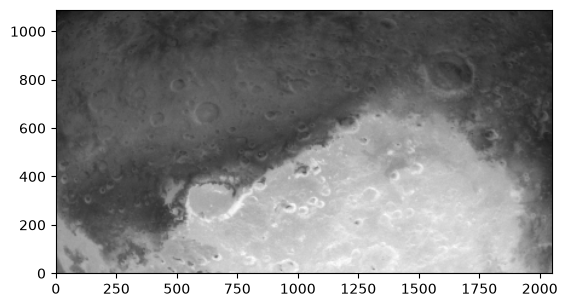

In [8]:
plt.imshow(sd_img, cmap = 'grey', origin = 'lower')
plt.show()

In [9]:
diff_err = hyp_img[:1088, :2048] - sd_img[:1088, :2048]

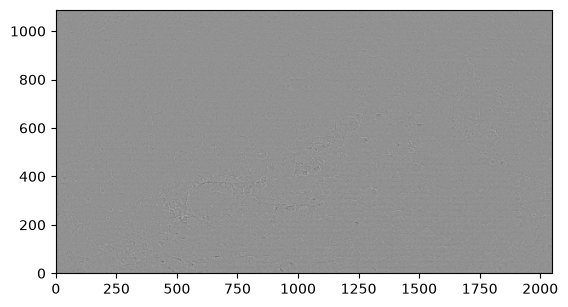

In [10]:
plt.imshow(diff_err, cmap = 'grey', origin = 'lower')
plt.show()

In [13]:
med_ae = np.median(np.abs(diff_err))

In [14]:
rmse = np.sqrt(np.mean((med_ae) ** 2))

In [15]:
print(f'Median Absolute Error = {med_ae} \nRMSE = {rmse * 100} %')

Median Absolute Error = 0.012739128722582233 
RMSE = 1.2739128722582231 %
